# Exploração inicial: nível do Guaíba (ANA)

**Objetivo:** entender que informações a base da ANA traz e como ela pode ser usada na Tela 2 do dashboard. Ainda não é a limpeza nem a EDA final.

**Fonte:** Agência Nacional de Águas e Saneamento Básico (ANA), serviço público de telemetria
<https://telemetriaws1.ana.gov.br/ServiceANA.asmx>. Os dados foram coletados por `scripts/coleta_ana_guaiba.py`. A data de cada requisição está em `dados/originais/ana/coleta_log.csv`.

**O que foi baixado:**

| Pasta | Conteúdo |
|---|---|
| `inventario/` | metadados das estações |
| `telemetria/` | leituras automáticas a cada 15 min, um arquivo por estação e por ano |
| `serie_historica/` | cotas diárias das estações convencionais (leitura manual), estações antigas |

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

PASTA = Path("../dados/originais/ana")

# Estilo: linhas finas, grade discreta, cores categóricas em ordem fixa por estação
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 12, "lines.linewidth": 1.4,
})
COR = {87450004: "#2a78d6", 87444000: "#eb6834", 87450020: "#1baf7a"}
COR_REF = "#52514e"   # linhas de referência (cotas, recorde)
COTA_ALERTA, COTA_INUNDACAO, RECORDE_2024 = 2.55, 3.00, 5.35


def ler_tabela(arquivo, tag):
    """Lê as linhas <tag> de um XML DataSet do serviço da ANA em um DataFrame."""
    linhas = []
    for _, elem in ET.iterparse(arquivo):
        if elem.tag == tag:
            linhas.append({filho.tag: (filho.text or "").strip() or None for filho in elem})
            elem.clear()
    return pd.DataFrame(linhas)

## 1. Estações

In [2]:
inventario = pd.concat(
    [ler_tabela(f, "Table") for f in sorted((PASTA / "inventario").glob("*.xml"))],
    ignore_index=True,
)
colunas = {"Codigo": "codigo", "Nome": "nome", "RioNome": "rio", "ResponsavelSigla": "responsavel",
           "Latitude": "lat", "Longitude": "lon", "PeriodoEscalaInicio": "escala_inicio",
           "PeriodoEscalaFim": "escala_fim", "Operando": "operando"}
estacoes = inventario[list(colunas)].rename(columns=colunas)
estacoes["codigo"] = estacoes["codigo"].astype(int)
NOMES = dict(zip(estacoes["codigo"], estacoes["nome"]))
estacoes

,codigo,nome,rio,responsavel,lat,lon,escala_inicio,escala_fim,operando
0,87444000,USINA DO GASÔMETRO (CHEIA 2024),RIO GUAÍBA,ANA,-30.0347,-51.2419,None,None,0
1,87450000,PORTO ALEGRE,RIO GUAÍBA,ANA,-30.0278,-51.2322,1929-08-01 00:00:00,1952-12-01 00:00:00,0
2,87450003,PRAÇA DA HARMONIA,RIO GUAÍBA,DNIT,-30.0347,-51.2414,1941-06-01 00:00:00,2008-12-01 00:00:00,0
3,87450004,CAIS MAUÁ C6,RIO GUAÍBA,SEMA-RS,-30.0211,-51.2211,2014-07-01 00:00:00,None,1
4,87450020,USINA DO GASÔMETRO,RIO GUAÍBA,ANA,-30.0347,-51.2419,None,None,1


São 5 estações. Três têm **telemetria**: Cais Mauá C6 e as duas da Usina do Gasômetro, instaladas na cheia de 2024. Duas são **convencionais antigas**: Porto Alegre e Praça da Harmonia.
Cada estação tem a própria régua, com o próprio zero. Por isso, valores de estações diferentes não podem ser comparados direto.

## 2. Telemetria: estrutura dos dados

In [3]:
partes = []
for f in sorted((PASTA / "telemetria").glob("*.xml")):
    df = ler_tabela(f, "DadosHidrometereologicos")
    if not df.empty:
        partes.append(df)
tele = pd.concat(partes, ignore_index=True)
print("Colunas originais:", list(tele.columns))
print("Linhas:", len(tele))
tele.head()

Colunas originais: ['CodEstacao', 'DataHora', 'Vazao', 'Nivel', 'Chuva']
Linhas: 438752


,CodEstacao,DataHora,Vazao,Nivel,Chuva
0,87444000,2024-12-31 23:45:00,None,156.00,0.00
1,87444000,2024-12-31 23:30:00,None,156.00,0.00
2,87444000,2024-12-31 23:15:00,None,155.00,0.00
3,87444000,2024-12-31 23:00:00,None,155.00,0.00
4,87444000,2024-12-31 22:45:00,None,156.00,0.00


In [4]:
tele = tele.rename(columns={"CodEstacao": "codigo", "DataHora": "data_hora",
                            "Nivel": "nivel_cm", "Chuva": "chuva_mm", "Vazao": "vazao"})
tele["codigo"] = tele["codigo"].astype(int)
tele["data_hora"] = pd.to_datetime(tele["data_hora"])
for col in ["nivel_cm", "chuva_mm", "vazao"]:
    tele[col] = pd.to_numeric(tele[col])
tele["nivel_m"] = tele["nivel_cm"] / 100

resumo = tele.groupby("codigo").agg(
    inicio=("data_hora", "min"), fim=("data_hora", "max"), leituras=("data_hora", "size"),
    pct_sem_nivel=("nivel_cm", lambda s: round(s.isna().mean() * 100, 1)),
    pct_com_chuva=("chuva_mm", lambda s: round(s.notna().mean() * 100, 1)),
    pct_com_vazao=("vazao", lambda s: round(s.notna().mean() * 100, 1)),
    nivel_min_m=("nivel_m", "min"), nivel_max_m=("nivel_m", "max"),
)
resumo.insert(0, "estacao", resumo.index.map(NOMES))
resumo

,estacao,inicio,fim,leituras,pct_sem_nivel,pct_com_chuva,pct_com_vazao,nivel_min_m,nivel_max_m
codigo,,,,,,,,,
87444000,USINA DO GASÔMETRO (CHEIA 2024),2024-05-03 00:00:00,2025-08-07 02:15:00,43921,0.3,90.2,0.0,0.99,5.35
87450004,CAIS MAUÁ C6,2014-07-27 18:30:00,2026-12-01 23:00:00,311217,3.9,99.1,0.0,0.03,3.90
87450020,USINA DO GASÔMETRO,2024-05-03 00:00:00,2026-10-26 19:15:00,83614,0.2,94.7,0.0,-0.19,4.17


In [5]:
duplicadas = tele.duplicated(["codigo", "data_hora"]).sum()
intervalos = (tele.sort_values("data_hora").groupby("codigo")["data_hora"].diff()
              .dt.total_seconds().div(60).value_counts().head(5))
print(f"Leituras duplicadas (mesma estação e horário): {duplicadas}")
print("Intervalos mais comuns entre leituras (minutos):")
print(intervalos)

Leituras duplicadas (mesma estação e horário): 0
Intervalos mais comuns entre leituras (minutos):
data_hora
15.0     429038
60.0       7497
120.0       616
75.0        299
180.0       222
Name: count, dtype: int64


In [6]:
coleta = pd.read_csv(PASTA / "coleta_log.csv", parse_dates=["data_coleta"])["data_coleta"].max()
futuras = tele[tele["data_hora"] > coleta]
print(f"Leituras com data posterior à coleta ({coleta:%d/%m/%Y}): {len(futuras)}")
print(futuras.groupby("codigo")["data_hora"].agg(["min", "max", "size"]))
print()
print("Leituras com nível negativo:")
print(tele[tele["nivel_cm"] < 0].groupby("codigo")["nivel_cm"].agg(["min", "size"]))

Leituras com data posterior à coleta (26/10/2026): 48
                min                 max  size
codigo                                       
87450004 2026-11-01 2026-12-01 23:00:00    48

Leituras com nível negativo:
           min  size
codigo              
87450020 -19.0   449


**O que temos na telemetria:**
- Uma leitura a cada **15 minutos**, com os campos `nivel_cm` (cota em cm), `chuva_mm` e `vazao`. A vazão vem sempre vazia nessas estações.
- Há leituras sem nível, que a limpeza vai precisar tratar.
- Há **leituras com data no futuro**, que não podem ser medições reais, e alguns **níveis negativos**. As duas coisas são inconsistências a registrar no relatório de limpeza.
- Para análise, faz mais sentido agregar por **dia**, usando o nível máximo do dia.

## 3. Cobertura: onde há buracos?

In [7]:
tele["data"] = tele["data_hora"].dt.normalize()
diario = (tele.dropna(subset=["nivel_m"])
          .groupby(["codigo", "data"])["nivel_m"].max().reset_index())

cobertura = (diario.assign(ano=diario["data"].dt.year)
             .groupby(["codigo", "ano"]).size().unstack("codigo").fillna(0).astype(int))
cobertura.columns = [f"{c} {NOMES[c]}" for c in cobertura.columns]
cobertura  # dias com pelo menos uma leitura de nível, por ano

,87444000 USINA DO GASÔMETRO (CHEIA 2024),87450004 CAIS MAUÁ C6,87450020 USINA DO GASÔMETRO
ano,,,
2014,0,126,0
2015,0,281,0
2016,0,296,0
2017,0,310,0
2018,0,347,0
2019,0,275,0
2020,0,366,0
2021,0,365,0
2022,0,365,0


## 4. Nível diário ao longo do tempo

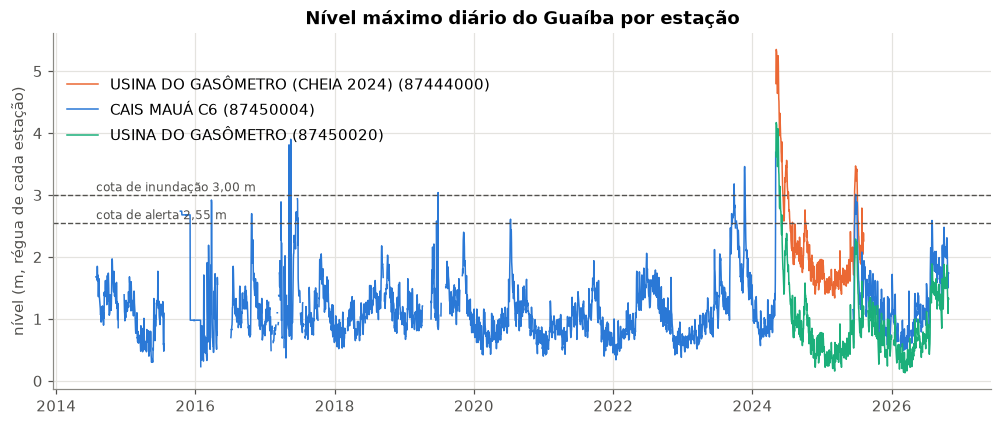

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for codigo, g in diario.groupby("codigo"):
    # reindexa para todos os dias, para a linha não "ligar" os buracos
    g = g.set_index("data")["nivel_m"].asfreq("D")
    ax.plot(g.index, g.values, color=COR[codigo], lw=1, label=f"{NOMES[codigo]} ({codigo})")
for y, rotulo in [(COTA_ALERTA, "cota de alerta 2,55 m"), (COTA_INUNDACAO, "cota de inundação 3,00 m")]:
    ax.axhline(y, color=COR_REF, lw=0.9, ls="--")
    ax.text(diario["data"].min(), y + 0.06, rotulo, color=COR_REF, fontsize=8)
ax.set_title("Nível máximo diário do Guaíba por estação")
ax.set_ylabel("nível (m, régua de cada estação)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92))
plt.show()

- Os trechos sem linha são períodos sem leitura.
- O Cais Mauá cobre de 2014 até hoje e é a régua de referência das cotas de alerta (2,55 m) e de inundação (3,00 m).
- Em **maio de 2024**, a série do Cais Mauá some, porque a régua foi perdida. O pico aparece só nas estações do Gasômetro.

## 5. Zoom na cheia de 2024

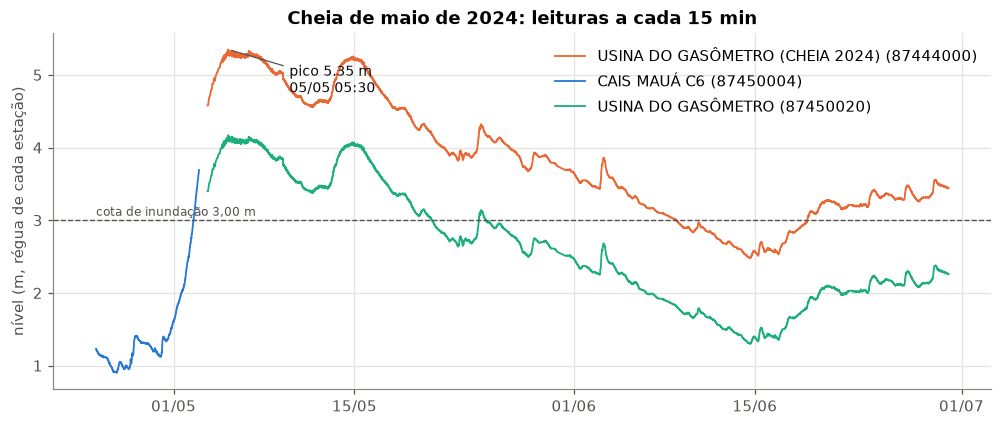

Última leitura do Cais Mauá antes do buraco: 2024-05-02 23:15:00


In [9]:
inicio, fim = "2024-04-25", "2024-06-30"
janela = tele[(tele["data_hora"] >= inicio) & (tele["data_hora"] <= fim)].dropna(subset=["nivel_m"])

fig, ax = plt.subplots(figsize=(11, 4.2))
for codigo, g in janela.groupby("codigo"):
    ax.plot(g["data_hora"], g["nivel_m"], color=COR[codigo], lw=1.2, label=f"{NOMES[codigo]} ({codigo})")
ax.axhline(COTA_INUNDACAO, color=COR_REF, lw=0.9, ls="--")
ax.text(pd.Timestamp(inicio), COTA_INUNDACAO + 0.06, "cota de inundação 3,00 m", color=COR_REF, fontsize=8)

pico = janela.loc[janela["nivel_m"].idxmax()]
ax.annotate(f"pico {pico['nivel_m']:.2f} m\n{pico['data_hora']:%d/%m %H:%M}",
            xy=(pico["data_hora"], pico["nivel_m"]), xytext=(40, -28),
            textcoords="offset points", fontsize=9, color="#0b0b0b",
            arrowprops=dict(arrowstyle="-", color=COR_REF, lw=0.8))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("Cheia de maio de 2024: leituras a cada 15 min")
ax.set_ylabel("nível (m, régua de cada estação)")
ax.legend(frameon=False, loc="upper right")
plt.show()

ultima_maua = janela[janela["codigo"] == 87450004]["data_hora"].max()
print(f"Última leitura do Cais Mauá antes do buraco: {ultima_maua}")

- O pico de **5,35 m** está na estação de emergência do Gasômetro (87444000), igual à marca citada no enunciado e usada na Tela 1.
- As duas estações do Gasômetro registram níveis bem diferentes no mesmo momento. A seção 6 mede essa diferença.

## 6. As réguas são comparáveis?

In [10]:
pares = diario.pivot(index="data", columns="codigo", values="nivel_m")
for a, b in [(87444000, 87450020), (87450004, 87450020)]:
    sobreposicao = pares[[a, b]].dropna()
    if sobreposicao.empty:
        print(f"{NOMES[a]} x {NOMES[b]}: sem dias em comum")
        continue
    dif = sobreposicao[a] - sobreposicao[b]
    print(f"{NOMES[a]} - {NOMES[b]}: {len(sobreposicao)} dias em comum, "
          f"diferença mediana {dif.median():+.2f} m (P10 {dif.quantile(.1):+.2f}, P90 {dif.quantile(.9):+.2f})")

USINA DO GASÔMETRO (CHEIA 2024) - USINA DO GASÔMETRO: 462 dias em comum, diferença mediana +1.18 m (P10 +1.18, P90 +1.18)
CAIS MAUÁ C6 - USINA DO GASÔMETRO: 455 dias em comum, diferença mediana +0.41 m (P10 +0.35, P90 +0.51)


- As duas estações do Gasômetro diferem em **exatamente 1,18 m** todos os dias. Provavelmente é o mesmo sensor, com o nível publicado em duas referências diferentes. Isso precisa ser confirmado com a ANA.
- Entre o Cais Mauá e o Gasômetro (87450020), a diferença fica em torno de **0,41 m**. É diferente dos 78 cm citados na imprensa para o desnível entre as estações, outro ponto a investigar.

A diferença entre as estações é grande e estável. Isso confirma que **cada estação mede em relação a um zero diferente**.
Uma série única de 2014 a 2026 exige um ajuste documentado. A alternativa é analisar cada estação separada e usar o Cais Mauá como referência das cotas oficiais.

## 7. Com que frequência o Guaíba passou da cota de inundação? (Cais Mauá)

In [11]:
maua = diario[diario["codigo"] == 87450004].set_index("data")["nivel_m"]
por_ano = pd.DataFrame({
    "dias_com_dado": maua.groupby(maua.index.year).size(),
    "nivel_max_m": maua.groupby(maua.index.year).max(),
    "dias_acima_alerta": (maua >= COTA_ALERTA).groupby(maua.index.year).sum(),
    "dias_acima_inundacao": (maua >= COTA_INUNDACAO).groupby(maua.index.year).sum(),
})
por_ano.index.name = "ano"
por_ano

,dias_com_dado,nivel_max_m,dias_acima_alerta,dias_acima_inundacao
ano,,,,
2014,126,1.97,0,0
2015,281,2.74,52,0
2016,296,2.92,5,0
2017,310,3.90,11,2
2018,347,2.18,0,0
2019,275,3.04,2,1
2020,366,2.61,2,0
2021,365,1.94,0,0
2022,365,2.06,0,0


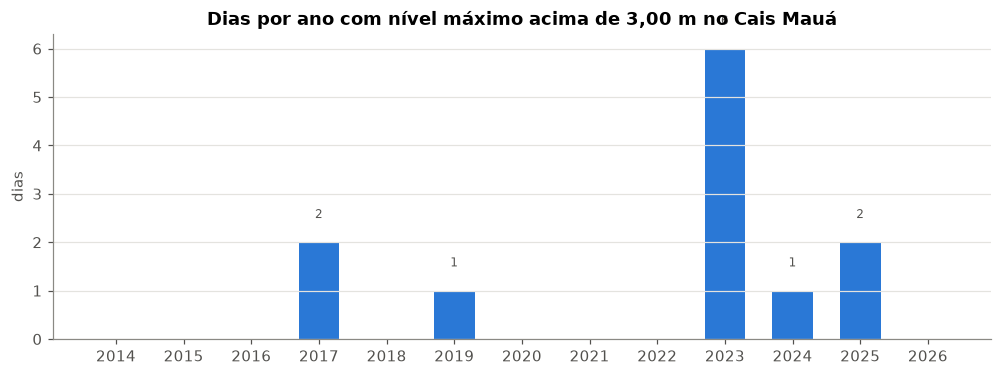

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(por_ano.index, por_ano["dias_acima_inundacao"], color=COR[87450004], width=0.6)
for ano, n in por_ano["dias_acima_inundacao"].items():
    if n > 0:
        ax.text(ano, n + 0.5, str(n), ha="center", fontsize=8, color="#52514e")
ax.set_title("Dias por ano com nível máximo acima de 3,00 m no Cais Mauá")
ax.set_ylabel("dias")
ax.set_xticks(por_ano.index)
ax.grid(axis="x", visible=False)
plt.show()

- Esta é uma das perguntas sugeridas no enunciado para a Tela 2.
- **Atenção a 2024:** a contagem está subestimada, porque faltam justamente os dias de nível mais alto. Isso precisa aparecer como limitação.
- Os anos têm números diferentes de dias com dado (coluna `dias_com_dado`). Anos com muitos buracos não são comparáveis sem esse aviso.

## 8. Sazonalidade: em que meses o rio sobe mais?

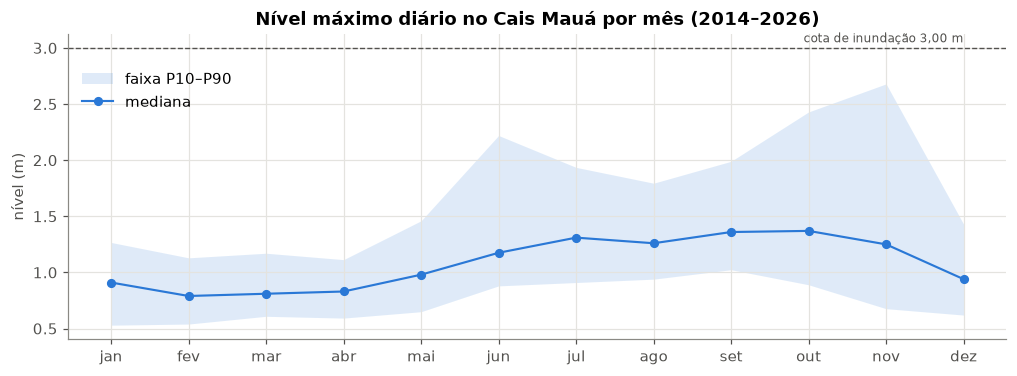

In [13]:
mensal = maua.groupby(maua.index.month)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(range(1, 13), mensal.quantile(0.1), mensal.quantile(0.9), color=COR[87450004], alpha=0.15,
                lw=0, label="faixa P10–P90")
ax.plot(range(1, 13), mensal.median(), color=COR[87450004], marker="o", ms=5, label="mediana")
ax.axhline(COTA_INUNDACAO, color=COR_REF, lw=0.9, ls="--")
ax.text(12, COTA_INUNDACAO + 0.05, "cota de inundação 3,00 m", color=COR_REF, fontsize=8, ha="right")
ax.set_xticks(range(1, 13), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_title("Nível máximo diário no Cais Mauá por mês (2014–2026)")
ax.set_ylabel("nível (m)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92))
plt.show()

O rio costuma ficar mais alto entre **junho e novembro** (inverno e primavera), e é nesses meses que a variação também é maior.

## 9. Séries históricas (estações convencionais)

In [14]:
hist = pd.concat(
    [ler_tabela(f, "SerieHistorica") for f in sorted((PASTA / "serie_historica").glob("*.xml"))],
    ignore_index=True,
)
print("Linhas (uma por mês):", len(hist))
print("Colunas:", list(hist.columns))
hist.groupby(["EstacaoCodigo", "NivelConsistencia"]).size().rename("meses")

Linhas (uma por mês): 980
Colunas: ['EstacaoCodigo', 'NivelConsistencia', 'DataHora', 'MediaDiaria', 'TipoMedicaoCotas', 'Maxima', 'Minima', 'Media', 'DiaMaxima', 'DiaMinima', 'MaximaStatus', 'MinimaStatus', 'MediaStatus', 'MediaAnualStatus', 'Cota01', 'Cota02', 'Cota03', 'Cota04', 'Cota05', 'Cota06', 'Cota07', 'Cota08', 'Cota09', 'Cota10', 'Cota11', 'Cota12', 'Cota13', 'Cota14', 'Cota15', 'Cota16', 'Cota17', 'Cota18', 'Cota19', 'Cota20', 'Cota21', 'Cota22', 'Cota23', 'Cota24', 'Cota25', 'Cota26', 'Cota27', 'Cota28', 'Cota29', 'Cota30', 'Cota31', 'Cota01Status', 'Cota02Status', 'Cota03Status', 'Cota04Status', 'Cota05Status', 'Cota06Status', 'Cota07Status', 'Cota08Status', 'Cota09Status', 'Cota10Status', 'Cota11Status', 'Cota12Status', 'Cota13Status', 'Cota14Status', 'Cota15Status', 'Cota16Status', 'Cota17Status', 'Cota18Status', 'Cota19Status', 'Cota20Status', 'Cota21Status', 'Cota22Status', 'Cota23Status', 'Cota24Status', 'Cota25Status', 'Cota26Status', 'Cota27Status', 'Cota28Status',

EstacaoCodigo  NivelConsistencia
87450000       1                    304
               2                    275
87450003       1                    401
Name: meses, dtype: int64

Aqui o formato é outro: **uma linha por mês**, com as colunas `Cota01` a `Cota31` (uma por dia) e os resumos `Maxima`, `Minima` e `Media`.
O campo `NivelConsistencia` indica 1 = dado bruto e 2 = dado consistido (revisado pela ANA). O mesmo mês pode aparecer duas vezes, e nesse caso a versão consistida deve ter preferência.

In [15]:
hist["codigo"] = hist["EstacaoCodigo"].astype(int)
hist["mes"] = pd.to_datetime(hist["DataHora"]).dt.to_period("M").dt.to_timestamp()
hist["consistencia"] = hist["NivelConsistencia"].astype(int)
# Fica com a versão consistida (2) quando existir
hist = hist.sort_values("consistencia").drop_duplicates(["codigo", "mes"], keep="last")

dias = [f"Cota{d:02d}" for d in range(1, 32)]
hist_longo = hist.melt(id_vars=["codigo", "mes"], value_vars=dias, var_name="dia", value_name="cota_cm")
hist_longo["data"] = hist_longo["mes"] + pd.to_timedelta(hist_longo["dia"].str[4:].astype(int) - 1, unit="D")
hist_longo = hist_longo[hist_longo["data"].dt.month == hist_longo["mes"].dt.month]  # descarta 30/02 etc.
hist_longo["nivel_m"] = pd.to_numeric(hist_longo["cota_cm"]) / 100
hist_longo = hist_longo.dropna(subset=["nivel_m"])

hist_longo.groupby("codigo").agg(inicio=("data", "min"), fim=("data", "max"),
                                 dias_com_dado=("data", "size"),
                                 nivel_min_m=("nivel_m", "min"), nivel_max_m=("nivel_m", "max"))

,inicio,fim,dias_com_dado,nivel_min_m,nivel_max_m
codigo,,,,,
87450000,1929-08-16,1980-12-31,8760,-0.15,4.63
87450003,1941-06-18,2008-03-31,11987,0.00,2.82


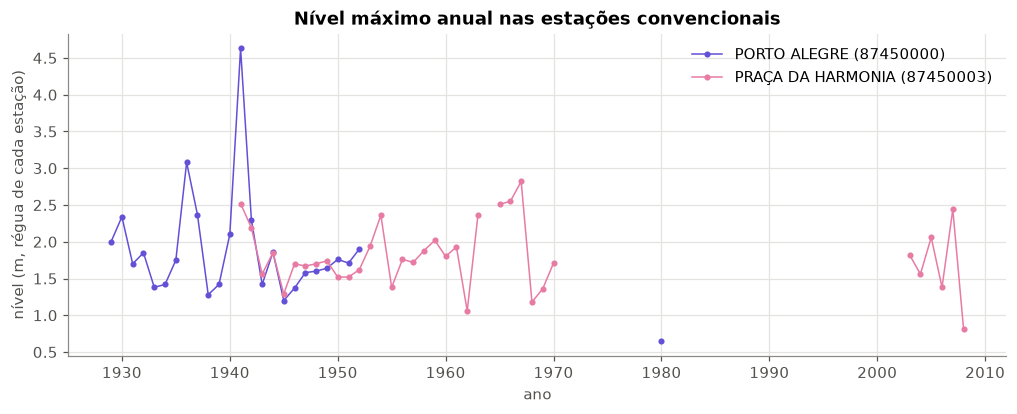

Maiores máximos anuais:
  codigo  data  max_m
87450000  1941   4.63
87450000  1936   3.08
87450003  1967   2.82
87450003  1966   2.55
87450003  1941   2.52


In [16]:
COR_HIST = {87450000: "#6250d6", 87450003: "#e87ba4"}
max_anual = hist_longo.groupby(["codigo", hist_longo["data"].dt.year])["nivel_m"].max().rename("max_m").reset_index()

fig, ax = plt.subplots(figsize=(11, 3.8))
for codigo, g in max_anual.groupby("codigo"):
    g = g.set_index("data")["max_m"]
    g = g.reindex(range(g.index.min(), g.index.max() + 1)).reset_index(name="max_m")  # anos sem dado viram buraco
    ax.plot(g["data"], g["max_m"], color=COR_HIST[codigo], marker="o", ms=3, lw=1,
            label=f"{NOMES[codigo]} ({codigo})")
ax.set_title("Nível máximo anual nas estações convencionais")
ax.set_xlabel("ano")
ax.set_ylabel("nível (m, régua de cada estação)")
ax.legend(frameon=False, loc="upper right")
plt.show()

print("Maiores máximos anuais:")
print(max_anual.sort_values("max_m", ascending=False).head(5).to_string(index=False))

- As séries antigas permitem olhar para trás, por exemplo para a cheia de **1941**. Mas elas têm muitos buracos e réguas com zeros diferentes do Cais Mauá. Os valores **não** podem ser colocados na mesma escala da cota de 3,00 m sem um ajuste.
- O inventário diz que a estação Porto Alegre (87450000) funcionou de 1929 a 1952, mas a série traz dados até décadas depois. Essa divergência vale ser investigada e documentada.

## 10. Resumo: o que temos e como usar

**Informações disponíveis**

| Base | Período | Resolução | Uso principal |
|---|---|---|---|
| Telemetria Cais Mauá C6 | 2014–2026 (buraco no pico de 2024) | 15 min | série recente na régua oficial das cotas de alerta e inundação |
| Telemetria Gasômetro (cheia 2024) | 2024–2025 | 15 min | pico de 5,35 m em maio/2024 |
| Telemetria Gasômetro | 2024–2026 | 15 min | continuidade depois da cheia |
| Convencionais (Porto Alegre, Praça da Harmonia) | décadas anteriores | diária | contexto histórico (1941), com cautela |

**Como a base conversa com a Tela 1**
1. **Pelo nível do Guaíba:** para o nível escolhido no slider da Tela 1, mostrar quantas vezes (dias ou anos) o rio chegou lá desde 2014. Isso dá a "frequência" de cada cenário da simulação.
2. **Pela enchente de 2024:** a curva de maio/2024 mostra quanto tempo o rio ficou acima de cada nível. Combinada com a Tela 1, ela indica quantas pessoas ficaram expostas e por quantos dias.
3. **Contexto:** dias por ano acima da cota de inundação e sazonalidade, mostrando que os meses de maior risco são o inverno e a primavera.

**Limitações para a limpeza e para o aviso no dashboard**
- Réguas diferentes, com zeros diferentes: não misturar estações sem ajuste documentado.
- O Cais Mauá não registrou o pico de 2024.
- Há leituras sem nível, anos com cobertura incompleta, datas no futuro e níveis negativos.
- É preciso confirmar o fuso horário de `DataHora` na documentação da ANA.
- O serviço usado é legado e pode ser desativado. Os XMLs brutos estão guardados em `dados/originais/ana/`.